# Energy Calculation

In [1]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
from qss import energy, entropy
from qss.distributions import prepare_2D_lattice_data, DistType

## Load $\mu$

In [3]:
mu_df = pd.read_csv("chemical_potential_results.csv")

In [4]:
n = np.unique(mu_df["n"])
distro = np.unique(mu_df["distro"])
k_BT = np.unique(mu_df["k_BT"])
H_a = np.unique(mu_df["H_a"])
mu_df = mu_df.set_index(["distro", "n", "k_BT", "H_a"])

## 2D Lattice

In [5]:
N = 100
t = -1
t_prim = 0.25
# t_prim = 0

kx = np.linspace(0, 2*np.pi*(N-1)/N, N+1) - np.pi
ky = np.linspace(0, 2*np.pi*(N-1)/N, N+1) - np.pi

e_k, _, _ = prepare_2D_lattice_data(kx, ky, t, t_prim)

## Energy

In [6]:
mu_df = pd.read_csv("chemical_potential_results.csv")
mu_df = mu_df.set_index(["distro", "n", "k_BT", "H_a"])

entropy_df = entropy(mu_df, e_k)
energy_df = energy(entropy_df, e_k)
energy_df

mu  iterations  converged  \
distro n        k_BT  H_a                                          
FD     0.100000 100.0 0.0     -294.454038          23       True   
       0.146842 100.0 0.0     -253.538484          21       True   
       0.193684 100.0 0.0     -223.290569          23       True   
       0.240526 100.0 0.0     -199.002595          23       True   
       0.287368 100.0 0.0     -178.510209          20       True   
...                                   ...         ...        ...   
NFLB   0.802632 0.1   10000.0   -0.516893          26       True   
       0.849474 0.1   10000.0   -0.414089          26       True   
       0.896316 0.1   10000.0   -0.308355          26       True   
       0.943158 0.1   10000.0   -0.200230          27       True   
       0.990000 0.1   10000.0   -0.090785          28       True   

                                   residual   entropy    energy  free_energy  
distro n        k_BT  H_a                                                     
FD     0.100000 100.0 0.0      1.448324e-08  0.397021 -0.002167   -39.704227  
       0.146842 100.0 0.0      4.373061e-08  0.524785 -0.003105   -52.481583  
       0.193684 100.0 0.0      9.474731e-08  0.636159 -0.003993   -63.619852  
       0.240526 100.0 0.0      3.452742e-09  0.734875 -0.004833   -73.492375  
       0.287368 100.0 0.0      1.499144e-07  0.823164 -0.005622   -82.322046  
...                                     ...       ...       ...          ...  
NFLB   0.802632 0.1   10000.0  2.709557e-08  0.428158 -0.629073    -0.671889  
       0.849474 0.1   10000.0  6.143487e-08  0.442947 -0.638502    -0.682797  
       0.896316 0.1   10000.0  1.075817e-08  0.456897 -0.645573    -0.691262  
       0.943158 0.1   10000.0  1.434111e-08  0.470946 -0.650127    -0.697222  
       0.990000 0.1   10000.0  5.739491e-09  0.485832 -0.652048    -0.700631  

[720 rows x 7 columns]

# Energy

#### $\frac{S} {k_B N} = f(n)$

<Axes: xlabel='n', ylabel='energy'>

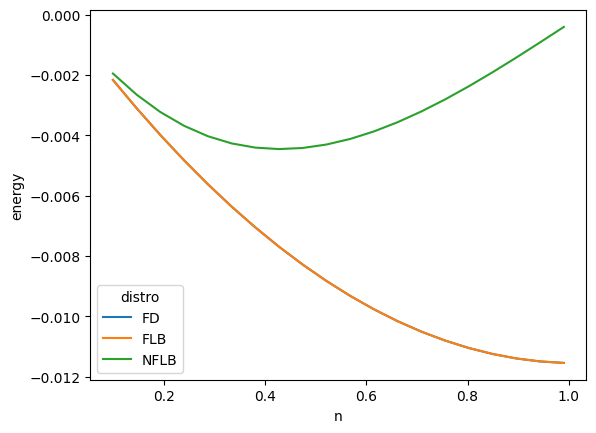

In [7]:
data = energy_df.loc[(distro, n, k_BT[-1], H_a[0]), :]
fig,ax = plt.subplots()
sns.lineplot(data= data, x="n", y="energy", hue="distro", markers=True, ax=ax)

## Free energy

$$ \frac{F}{N |t|} =  \frac{1}{N |t|}  \sum_k \epsilon_k n_k - \frac{k_bT}{|t|} \frac{S}{k_bN}$$


<Axes: xlabel='n', ylabel='free_energy'>

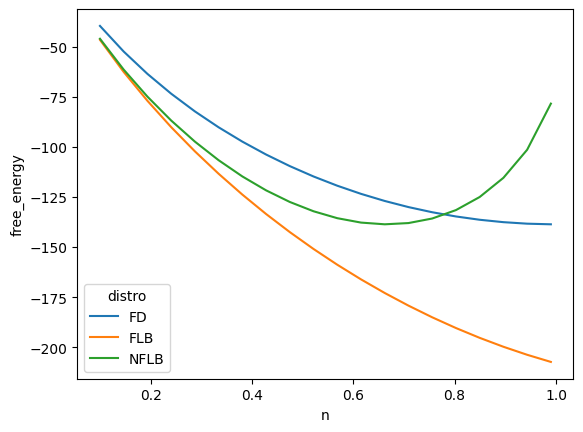

In [8]:
data = energy_df.loc[(distro, n, k_BT[-1], H_a[0]), :]
fig,ax = plt.subplots()
sns.lineplot(data= data, x="n", y="free_energy", hue="distro", markers=True, ax=ax)